# Symbolic Regression on Feynman Equations using Genetic Programming

Symbolic regression is a type of regression analysis where the goal is to discover mathematical expressions that best describe a given dataset. Unlike traditional regression, symbolic regression does not assume a predefined model structure. Instead, it searches for both the structure and the parameters that best fit the data. This approach can yield interpretable, analytical models that help uncover underlying relationships in the data.

In this notebook, we will apply symbolic regression to a set of well-known physical equations: the Feynman Equations. These equations, derived by physicist Richard Feynman, describe fundamental physical phenomena in areas such as mechanics, electromagnetism, and thermodynamics.

We will perform symbolic regression with **genetic programming** (GP), using `gplearn`, a `scikit-learn`-inspired Python library for GP.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import gplearn.genetic as gp
import matplotlib.pyplot as plt
import graphviz
import pickle

Read the metadata of the equations from the csv file plus the equations from the pickle file.

In [2]:
eq_df = pd.read_csv('data/FeynmanEquations.csv')
eq_df = eq_df.dropna(axis = 0, how = 'all')
eq_df.head()

,Filename,Number,Output,Formula,# variables,v1_name,v1_low,v1_high,v2_name,v2_low,...,v7_high,v8_name,v8_low,v8_high,v9_name,v9_low,v9_high,v10_name,v10_low,v10_high
0,I.6.2a,1.0,f,exp(-theta**2/2)/sqrt(2*pi),1.0,theta,1.0,3.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,I.6.2,2.0,f,exp(-(theta/sigma)**2/2)/(sqrt(2*pi)*sigma),2.0,sigma,1.0,3.0,theta,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,I.6.2b,3.0,f,exp(-((theta-theta1)/sigma)**2/2)/(sqrt(2*pi)*...,3.0,sigma,1.0,3.0,theta,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,I.8.14,4.0,d,sqrt((x2-x1)**2+(y2-y1)**2),4.0,x1,1.0,5.0,x2,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,I.9.18,5.0,F,G*m1*m2/((x2-x1)**2+(y2-y1)**2+(z2-z1)**2),9.0,m1,1.0,2.0,m2,1.0,...,2.0,z1,3.0,4.0,z2,1.0,2.0,NaN,NaN,NaN


In [3]:
datasets = {}
with open("./data/feynman_eq_3_8.pkl", "rb") as f:
    datasets = pickle.load(f)

Now, for each equation in the dataset, perform symbolic regression using GP. Split each dataset into a training set and a validation set. Select a validation metric to evaluate performance, noting that this metric is not necessarily the same as the GP fitness function. Experiment with different sets of hyperparameters to observe how the results change.

Take a look at the [documentation](https://gplearn.readthedocs.io/en/stable/intro.html).

Define some function with `make_function`.

In [5]:
from gplearn.functions import make_function

def _protected_exponent(x):
    with np.errstate(over='ignore'):
        return np.where(np.abs(x) < 100, np.exp(x), 0.)
    
def _square(x):
    return x**2
    
exp = make_function(function=_protected_exponent,
                        name='exp',
                        arity=1)

square = make_function(function=_square,
                        name='square',
                        arity=1)


Set the hyperparameters.

In [8]:
random_state = 0

#hyperparameters
max_gen = 5
fset = ('add', 'sub', 'mul', 'div', 'sqrt', exp, square)
pop_size = 1500
tournament_size = 20
parsimony_coefficient = 0.015
p_crossover=0.9
p_subtree_mutation = 0.03
p_hoist_mutation=0.01
p_point_mutation=0.01
fitness = 'rmse'
val_fit = r2_score

And now create the optimization loop.

Iterate over each dataset in the dictionary, collect the results (as described by the definition of `results`) and collect the validation fitness history (to later print them).

During each cycle take X and y from the dataset (X = the entire dataset without the target), y is the target. Remember to convert them to numpy ndarray.

Use train_test_split in order to divide into training and test set.

Use the name of the columns (without the target one) as feature names.

Instantiate a `gp.SymbolicRegressor` with all the hyperparameters set before (set `generations` to 1 and `warm_start=True`) and then loop over the generations. Each generation must:

1. set the parameters
2. fit to X and y (train set)
3. compute the validation error (test set)
4. store the value to later plot

Once the generation is ended, store the final results and go on.

In [15]:
np.random.seed(random_state)
results = pd.DataFrame(columns=['dataset','best_fit', 'original', 'equation'])
val_histories = {}

for name, df in datasets.items():
    X = df.drop('target', axis=1).to_numpy()
    y = df[['target']].to_numpy().flatten()
    X_train, X_val, y_train, y_val = train_test_split(X, y, train_size=0.75, test_size=0.25, random_state=random_state)
    
    val_history = []
    var_names = df.drop(columns=['target']).columns.tolist()
    
    sr = gp.SymbolicRegressor(population_size=pop_size,
                                tournament_size=tournament_size,
                                function_set=fset,
                                parsimony_coefficient=parsimony_coefficient,
                                p_crossover=p_crossover,
                                p_subtree_mutation=p_subtree_mutation, # Probability of subtree mutation
                                p_hoist_mutation=p_hoist_mutation, # Small probability of hoist mutation
                                p_point_mutation=p_point_mutation, # Small probability of point mutation
                                generations=1,
                                random_state=random_state,
                                feature_names=var_names,
                                warm_start=True,
                                metric=fitness,
    )

    for i in range(0, max_gen+1):
        sr.set_params(generations=i+1)
        sr.fit(X_train, y_train)
        y_pred = sr.predict(X_val)
        val_history.append(val_fit(y_val, y_pred))

    correct_name = str(name).strip("feynman_").replace("_", ".")

    orig = eq_df[eq_df.Filename == correct_name]['Formula'].tolist()

    best_fit = val_history[-1]
    val_histories[name] = val_history
    results.loc[len(results)] = [name, best_fit, orig[0], sr._program]
    print(f'{name} best_fit: {best_fit}')

print("------------------------------------")
print(results)

c:\Users\Utente\Documents\Tutorato\Optimization for AI\Optimization4AI\.venv\Lib\site-packages\gplearn\fitness.py:137: RuntimeWarning: overflow encountered in square
  return np.sqrt(np.average(((y_pred - y) ** 2), weights=w))


feynman_I_8_14 best_fit: 0.4617684891961985
feynman_I_9_18 best_fit: -0.02632018988032825


c:\Users\Utente\Documents\Tutorato\Optimization for AI\Optimization4AI\.venv\Lib\site-packages\gplearn\fitness.py:137: RuntimeWarning: overflow encountered in square
  return np.sqrt(np.average(((y_pred - y) ** 2), weights=w))


feynman_I_10_7 best_fit: 0.9729916311434271
feynman_I_11_19 best_fit: 1.0


c:\Users\Utente\Documents\Tutorato\Optimization for AI\Optimization4AI\.venv\Lib\site-packages\gplearn\fitness.py:137: RuntimeWarning: overflow encountered in square
  return np.sqrt(np.average(((y_pred - y) ** 2), weights=w))


feynman_I_12_1 best_fit: 1.0


c:\Users\Utente\Documents\Tutorato\Optimization for AI\Optimization4AI\.venv\Lib\site-packages\gplearn\fitness.py:137: RuntimeWarning: overflow encountered in square
  return np.sqrt(np.average(((y_pred - y) ** 2), weights=w))


feynman_I_12_2 best_fit: -0.02459533657681634
------------------------------------
           dataset  best_fit                                    original  \
0   feynman_I_8_14  0.461768                 sqrt((x2-x1)**2+(y2-y1)**2)   
1   feynman_I_9_18 -0.026320  G*m1*m2/((x2-x1)**2+(y2-y1)**2+(z2-z1)**2)   
2   feynman_I_10_7  0.972992                       m_0/sqrt(1-v**2/c**2)   
3  feynman_I_11_19  1.000000                           x1*y1+x2*y2+x3*y3   
4   feynman_I_12_1  1.000000                                       mu*Nn   
5   feynman_I_12_2 -0.024595                 q1*q2*r/(4*pi*epsilon*r**3)   

                                          equation  
0          exp(sqrt(div(sub(y1, y2), exp(0.797))))  
1                                      sqrt(0.093)  
2                                              m_0  
3  add(mul(x3, y3), add(mul(x1, y1), mul(y2, x2)))  
4                                      mul(mu, Nn)  
5                                            0.072  


Plot the loss histories!

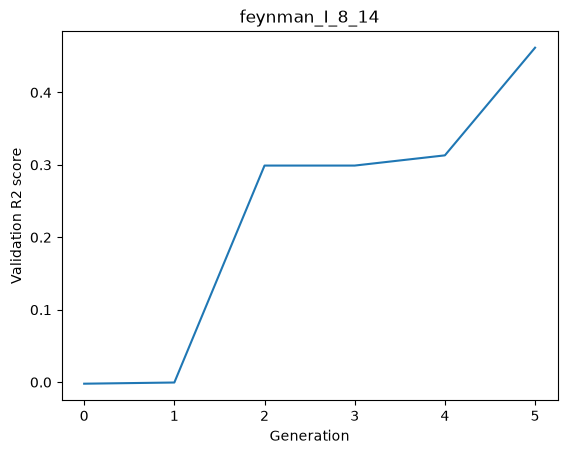

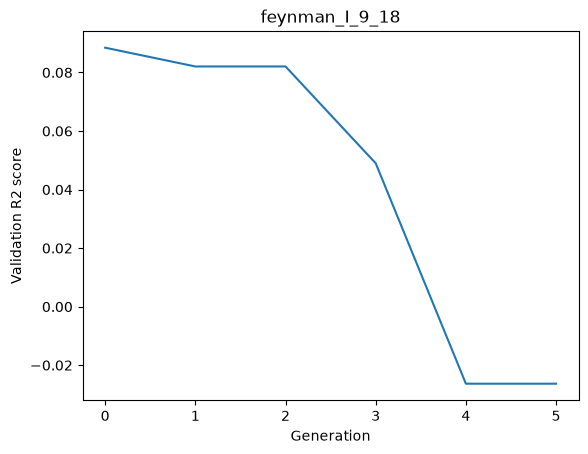

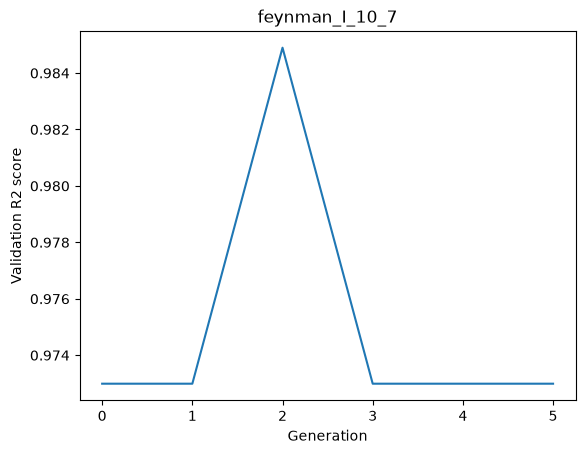

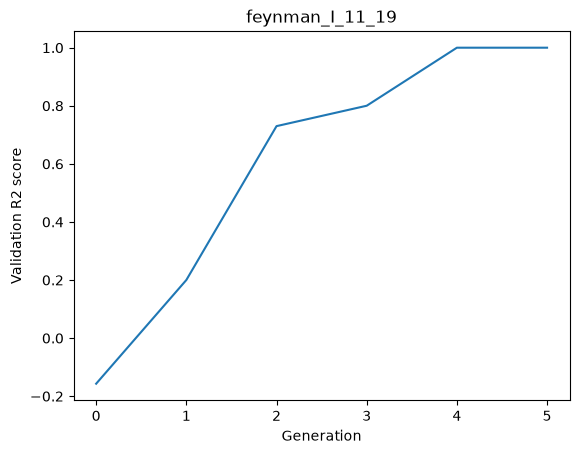

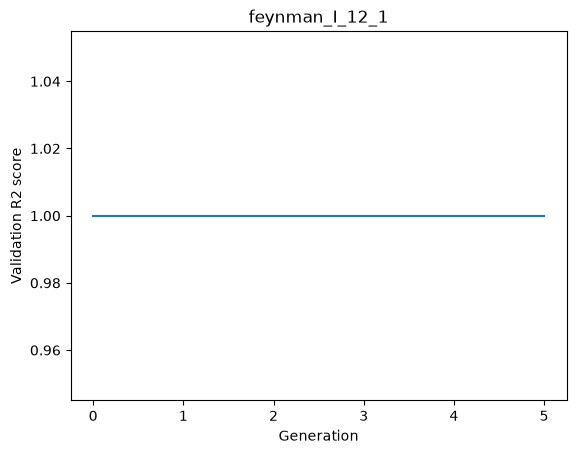

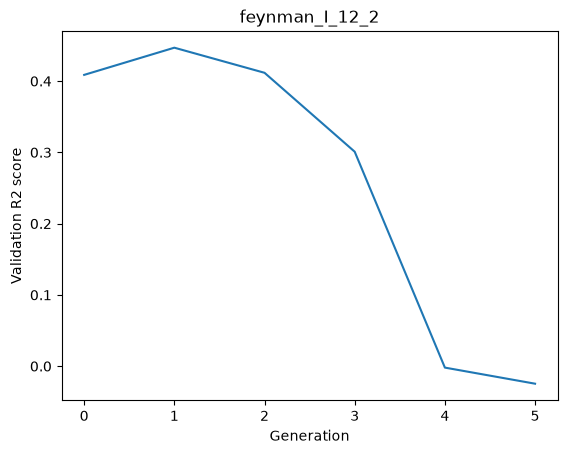

In [16]:
for name, history in val_histories.items():
    plt.plot(history)
    plt.ylabel('Validation R2 score')
    plt.xlabel('Generation')
    plt.title(name)
    plt.show()

You can also try this simple tool to visualize a bit the solution found.

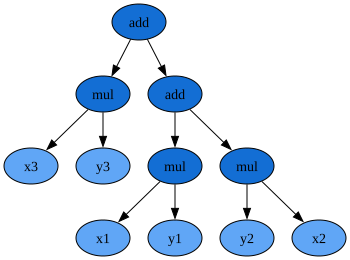

In [11]:
dot_data=results.loc[3, "equation"].export_graphviz()
graphviz.Source(dot_data)